# **A Predictive Model for Wine Quality Evaluation**

## **Learning Gate**
#### **Tecnológico de Monterrey**

**Name:**

*   René de la Calleja

**Creation Date:**

*   Aug/25/2026

# 1. Loading and Exploring the Data (EDA)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Loading the dataset in a Pandas DataFrame.
df_wine = pd.read_csv('datos_VinoMaster.csv', delimiter=",")

# 2. Showing dataset dimensions
print(f"dataset shape (rows, columns): {df_wine.shape}\n")

# 3. Showing the first rows
print("First dataset rows:")
pd.set_option('display.max_columns', None) # Set option to display all columns
df_wine.head(10)

dataset shape (rows, columns): (6497, 14)

First dataset rows:


,id,Type,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,id0001,red,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
1,id0002,white,7.4,0.14,0.30,1.3,0.033,25.0,91.0,0.99268,3.53,0.39,10.6,6
2,id0003,white,6.6,0.18,0.28,1.7,0.041,53.0,161.0,0.99207,3.13,0.45,10.2,6
3,id0004,white,6.6,0.22,0.37,15.4,0.035,62.0,153.0,0.99845,3.02,0.40,9.3,5
4,id0005,white,6.5,0.18,0.26,1.4,0.041,40.0,141.0,0.99410,3.34,0.72,9.5,6
5,id0006,white,6.8,0.23,0.29,15.4,0.073,56.0,173.0,0.99840,3.06,0.41,8.7,6
6,id0007,white,7.0,0.15,0.30,13.3,0.049,46.0,120.0,0.99704,3.20,0.36,9.5,7
7,id0008,red,9.6,0.41,0.37,2.3,0.091,10.0,23.0,0.99786,3.24,0.56,10.5,5
8,id0009,white,6.1,0.36,0.16,6.4,0.037,36.0,198.0,0.99440,3.17,0.62,9.9,6
9,id0010,white,6.5,0.23,0.45,2.1,0.027,43.0,104.0,0.99054,3.02,0.52,11.3,6


In [ ]:
print("--- Variable Types in the Dataset ---")
df_wine.info()
print("\n" + "="*50 + "\n")

#  Finding missing values per variable
print("--- Missing values per variable ---")
missing_values = df_wine.isnull().sum()
print(missing_values[missing_values > 0] if missing_values.sum() > 0 else "No missing values in the dataset.")
print("\n" + "="*50 + "\n")


--- Variable Types in the Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    6497 non-null   object 
 1   Type                  6497 non-null   object 
 2   fixed acidity         6497 non-null   float64
 3   volatile acidity      6497 non-null   float64
 4   citric acid           6497 non-null   float64
 5   residual sugar        6497 non-null   float64
 6   chlorides             6497 non-null   float64
 7   free sulfur dioxide   6497 non-null   float64
 8   total sulfur dioxide  6497 non-null   float64
 9   density               6497 non-null   float64
 10  pH                    6497 non-null   float64
 11  sulphates             6497 non-null   float64
 12  alcohol               6497 non-null   float64
 13  quality               6497 non-null   int64  
dtypes: float64(11), int64(1), object(2

In [ ]:
print("--- Basic data statistics ---")
df_wine.describe()

--- Basic data statistics ---


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000,6497.000000
mean,7.215307,0.339666,0.318633,5.443235,0.056034,30.525319,115.744574,0.994697,3.218501,0.531268,10.491801,5.818378
std,1.296434,0.164636,0.145318,4.757804,0.035034,17.749400,56.521855,0.002999,0.160787,0.148806,1.192712,0.873255
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,77.000000,0.992340,3.110000,0.430000,9.500000,5.000000
50%,7.000000,0.290000,0.310000,3.000000,0.047000,29.000000,118.000000,0.994890,3.210000,0.510000,10.300000,6.000000
75%,7.700000,0.400000,0.390000,8.100000,0.065000,41.000000,156.000000,0.996990,3.320000,0.600000,11.300000,6.000000
max,15.900000,1.580000,1.660000,65.800000,0.611000,289.000000,440.000000,1.038980,4.010000,2.000000,14.900000,9.000000


/tmp/ipykernel_2156/4135384064.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='quality', data=df_wine, palette='viridis')


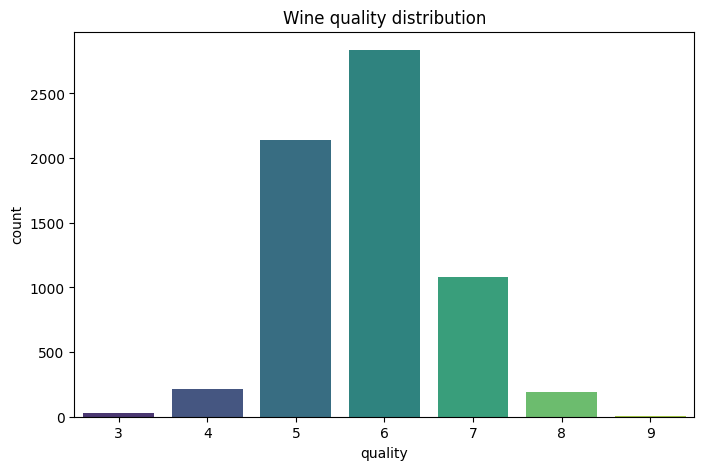

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(x='quality', data=df_wine, palette='viridis')
plt.title('Wine quality distribution')
plt.show()

### Performing more data exploration

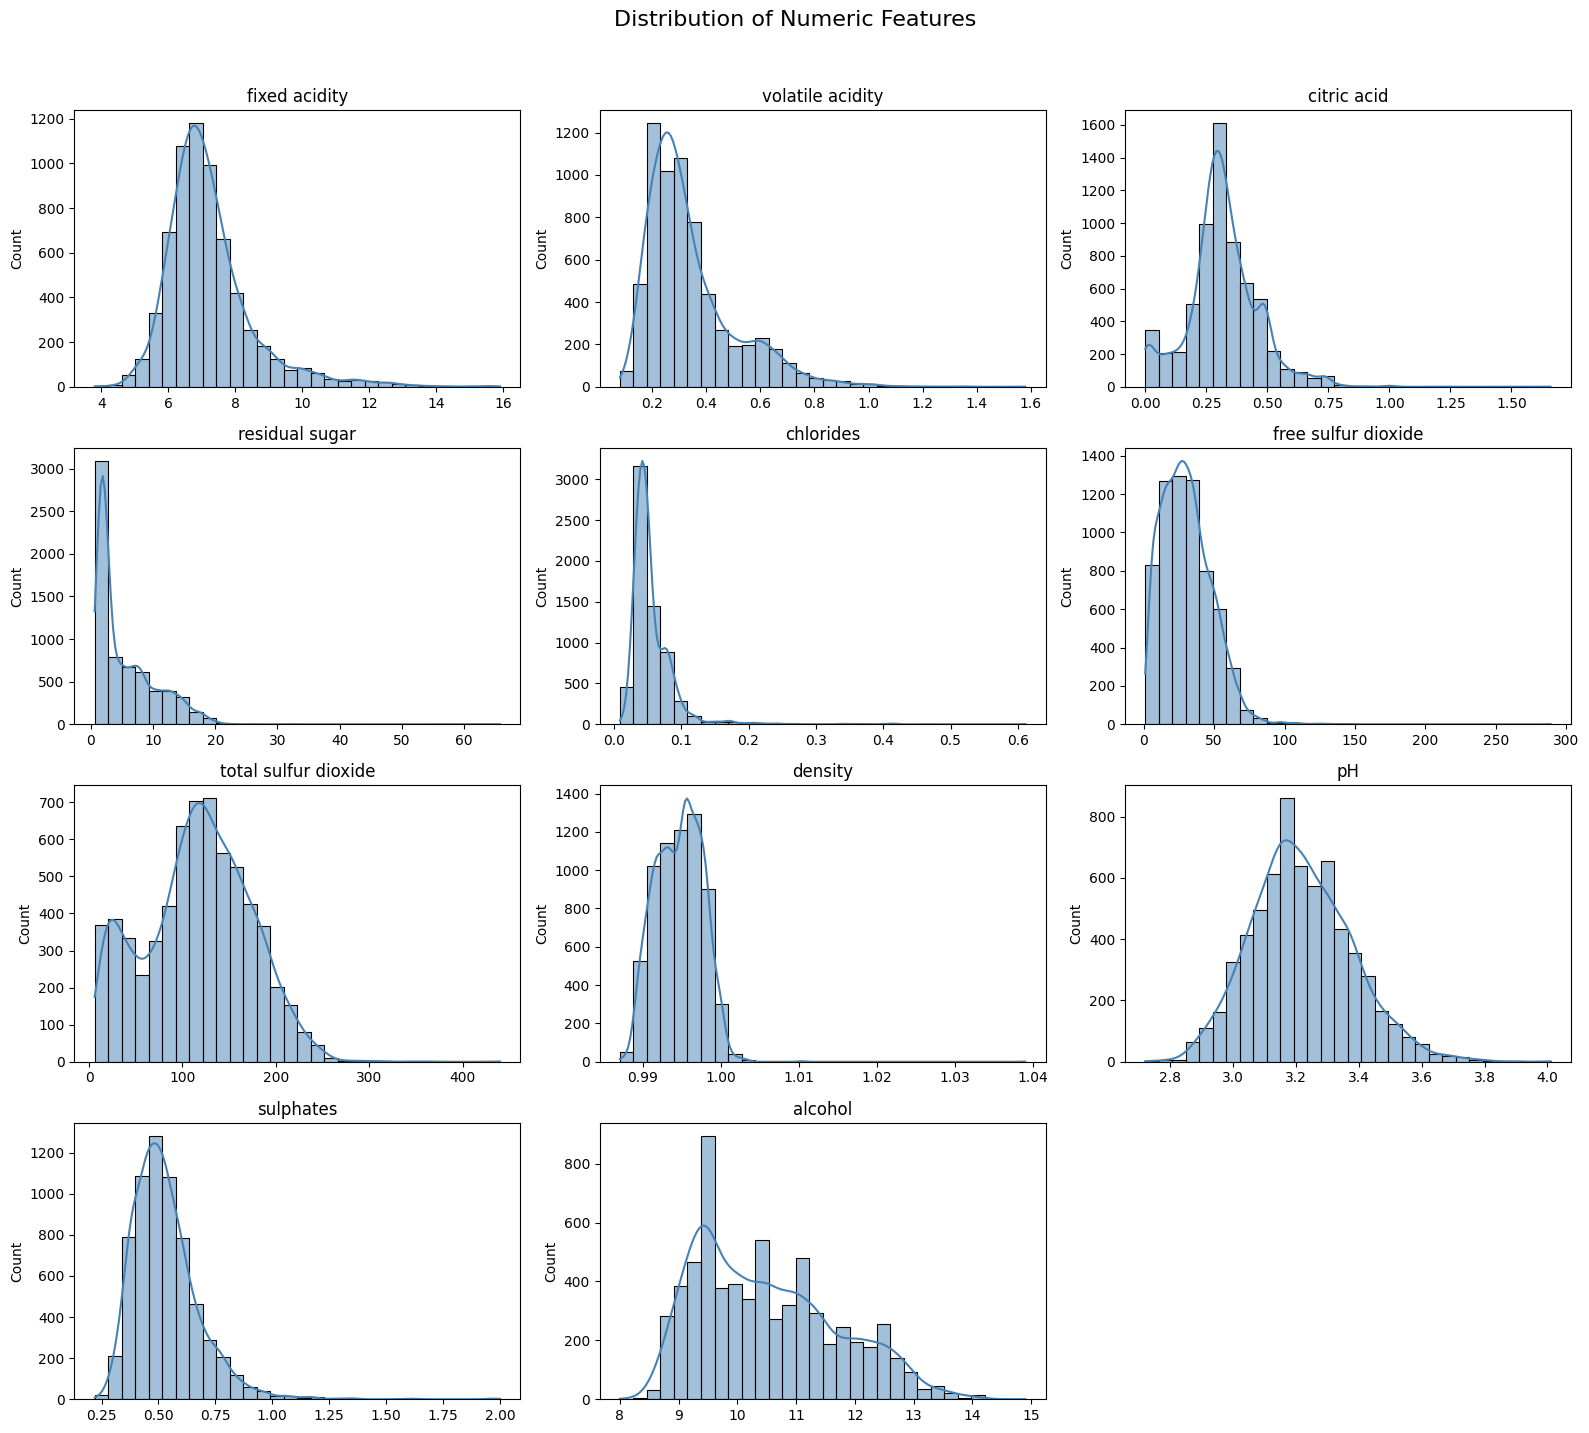

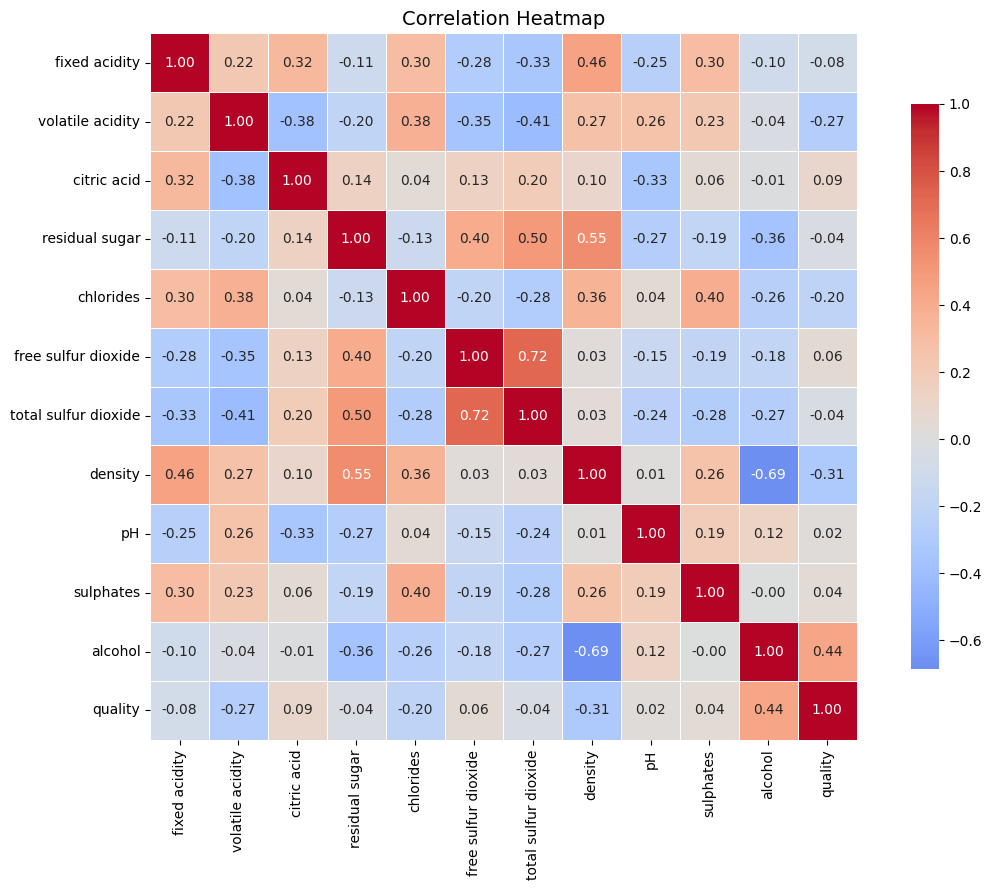

Correlation with quality (sorted by absolute value):
alcohol                 0.444319
density                -0.305858
volatile acidity       -0.265699
chlorides              -0.200666
citric acid             0.085532
fixed acidity          -0.076743
free sulfur dioxide     0.055463
total sulfur dioxide   -0.041385
sulphates               0.038485
residual sugar         -0.036980
pH                      0.019506
Name: quality, dtype: float64


/tmp/ipykernel_2156/3997723453.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df_wine, ax=axes[i], palette='viridis')
/tmp/ipykernel_2156/3997723453.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df_wine, ax=axes[i], palette='viridis')
/tmp/ipykernel_2156/3997723453.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality', y=col, data=df_wine, ax=axes[i], palette='viridis')
/tmp/ipykernel_2156/3997723453.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is 

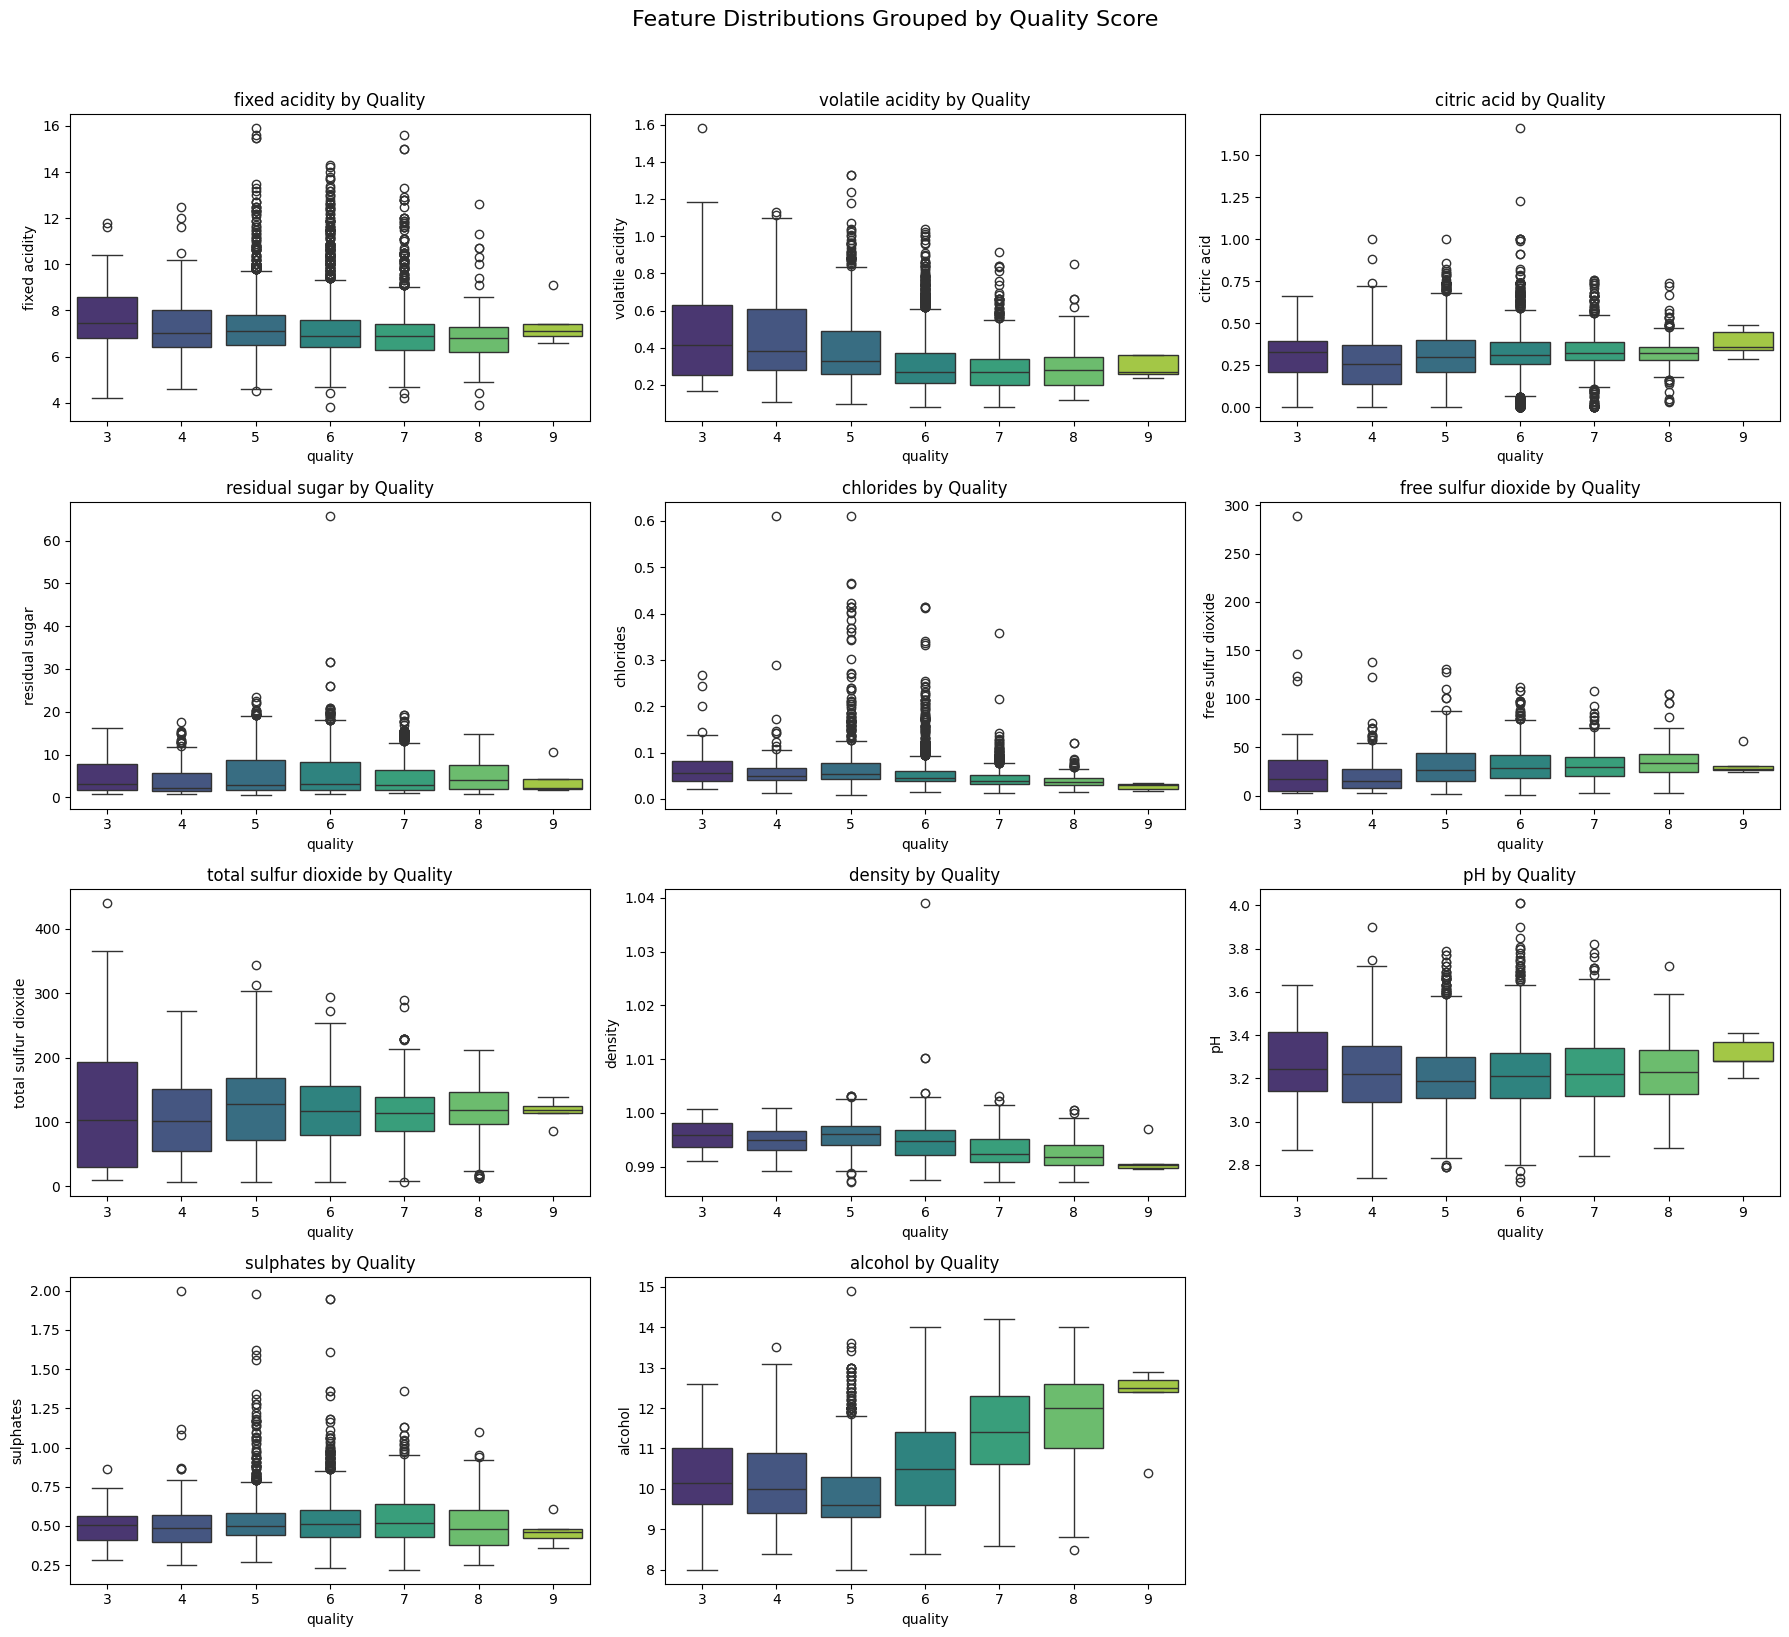

In [ ]:
import numpy as np

# List of numeric feature columns (excluding id and quality/target)
numeric_features = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide',
    'density', 'pH', 'sulphates', 'alcohol'
]

# ------------------------------------------------------------------
# 1. Univariate distributions of features (histograms + KDE)
# ------------------------------------------------------------------
fig, axes = plt.subplots(4, 3, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.histplot(df_wine[col], kde=True, ax=axes[i], color='steelblue', bins=30)
    axes[i].set_title(col)
    axes[i].set_xlabel('')

# hide unused subplot (11 features -> 12 slots)
for j in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Distribution of Numeric Features', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 3. Correlation heatmap
# ------------------------------------------------------------------
corr_matrix = df_wine[numeric_features + ['quality']].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'shrink': 0.8}
)
plt.title('Correlation Heatmap', fontsize=14)
plt.tight_layout()
plt.show()

# Quick look at which features correlate most with quality
quality_corr = corr_matrix['quality'].drop('quality').sort_values(key=abs, ascending=False)
print("Correlation with quality (sorted by absolute value):")
print(quality_corr)

# ------------------------------------------------------------------
# 4. Feature vs. target boxplots (grouped by quality score)
# ------------------------------------------------------------------
fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    sns.boxplot(x='quality', y=col, data=df_wine, ax=axes[i], palette='viridis')
    axes[i].set_title(f'{col} by Quality')

for j in range(len(numeric_features), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle('Feature Distributions Grouped by Quality Score', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

**Some first insights from the data exploration:**

**Volatile acidity** — clear downward trend: median volatile acidity drops steadily from quality 3 to quality 9. It's likely one of the stronger predictive features.

**Chlorides** — mild downward trend with a lot of high-value outliers concentrated at quality 5 and 6. Lower chloride content tends to associate with higher quality, but the signal is noisier than volatile acidity due to those outliers.

**Citric acid** — slight upward trend, though weak. Medians inch up a bit toward higher quality but there's a lot of overlap between groups.

**Fixed acidity** — no strong trend; medians stay fairly flat around 7-7.5 across all quality levels. This is likely a weak predictor on its own.

**Residual sugar** — no clear trend, heavily right-skewed with many outliers (as expected from the earlier histogram). Probably not a strong standalone predictor, and its skew is something we'll need to handle before feeding into MLPRegressor.

**Free sulfur dioxide / total sulfur dioxide** — both show a slight rise-then-fall pattern (increase from quality 3 to mid-range, then decrease toward 8-9), rather than a monotonic trend. This "inverted U" shape suggests a non-linear relationship — a good argument for using a neural net (MLPRegressor) instead of a purely linear model.

**Density** — slight downward trend, very tight boxes (density has a very narrow range naturally, ~0.99-1.04), with a few extreme outliers at low quality. This tightness means small numeric differences may still be meaningful — scaling will be very important for this feature with MLPRegressor.

**pH **— basically flat, no visible trend. Weak predictor on its own.

**Alcohol** — this is the standout. There's a clear, strong pattern: quality 3-5 have lower median alcohol (~9.5-10.5), then a distinct jump upward from quality 5 onward, climbing steadily to ~12.5 at quality 9. Probably this is the single strongest predictor.

**Sulphates** — mild but visible upward trend from quality 3 through 7 (medians creep up from ~0.47 to ~0.55), then it flattens/dips slightly at 8-9. Lots of high-value outliers cluster around quality 5-6. Weaker signal than alcohol, but still likely useful, especially in combination with other features.

Updated overall ranking of visual signal strength, from what you've shown so far:

1. Alcohol — strongest, clear monotonic-ish trend

2. Volatile acidity — strong, clear downward trend

3. Chlorides — moderate downward trend

4. Sulphates — mild upward trend

5. Density — mild downward trend

6. Sulfur dioxide (free/total) — non-linear (rise then fall)

7. Citric acid — weak upward trend

8. Fixed acidity, pH, residual sugar

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df_wine[numeric_features]  # add 'Type' separately to encode it
X['Type'] = (df_wine['Type'] == 'red').astype(int)
y = df_wine['quality']

# 1. Split FIRST
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Fit scaler on training data only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# 3. Use the SAME fitted scaler to transform test data (transform, not fit_transform)
X_test_scaled = scaler.transform(X_test)

/tmp/ipykernel_2156/3160655921.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Type'] = (df_wine['Type'] == 'red').astype(int)


# Training and testing different MLPRegressor configurations.

## Testing as a first approach.

In [ ]:
# Testing first with a small MLPRegressor

from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score

nn_model = MLPRegressor(
    hidden_layer_sizes=(6,6),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))

Neural Network MSE: 0.474043025624051
Neural Network R^2: 0.33705817339333877
Evaluation (training set): 0.399515
Evaluation (test set): 0.337058


In [ ]:
# Increasing the number of Max iterations.

nn_model = MLPRegressor(
    hidden_layer_sizes=(6,6),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=4000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))

Neural Network MSE: 0.474043025624051
Neural Network R^2: 0.33705817339333877
Evaluation (training set): 0.399515
Evaluation (test set): 0.337058


In [ ]:
# Increasing the number of neurons in the first layer.
nn_model = MLPRegressor(
    hidden_layer_sizes=(8,6),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))

Neural Network MSE: 0.48683497947475546
Neural Network R^2: 0.3191688241291232
Evaluation (training set): 0.379784
Evaluation (test set): 0.319169


In [ ]:
# Adding a third layer with four neurons.

nn_model = MLPRegressor(
    hidden_layer_sizes=(6,6,4),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=3000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))

Neural Network MSE: 0.4706703031070053
Neural Network R^2: 0.34177487357713376
Evaluation (training set): 0.388972
Evaluation (test set): 0.341775


In [ ]:
# Let's try now with a bigger network

nn_model = MLPRegressor(
    hidden_layer_sizes=(64,32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))


Neural Network MSE: 0.55490678976633
Neural Network R^2: 0.22397145212747738
Evaluation (training set): 0.520357
Evaluation (test set): 0.223971


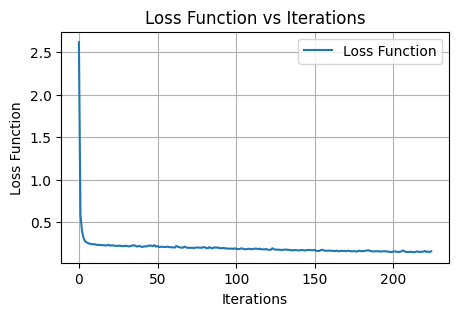

In [ ]:
# Let's check for convergence.

loss_curve = nn_model.loss_curve_
plt.figure(figsize=(5, 3))
plt.plot(loss_curve, label='Loss Function')
plt.title('Loss Function vs Iterations')
plt.xlabel('Iterations')
plt.ylabel('Loss Function')
plt.legend()
plt.grid(True)
plt.show()

**Some insights from these experiments:**

The first small model (6,6) went not so bad considering the problem we are tackling, because quality scores are subjective sensory ratings (given by human tasters) that don't map cleanly onto the chemical measurements.

The next significant change was to try with a larger model with more capacity (more neurons in the layers (64,32)) and these are the main results:

	                  Small (6,6)	  Bigger (64,32)
       Train R²       0.3995            0.5204
       Test R²        0.3371            0.2240
       Test MSE       0.4740            0.5549
       Train-Test gap ~0.06	            ~0.30

So it clearly went worse, the training score jumped up substantially (the bigger network is fitting the training data much better), but test performance got worse across the board. The train-test gap went from small (0.06) to large (0.30). So we have overfitting here, and this is due probably because the training process runs through too many iterations and memorizes patterns specific to the training set that don't generalize.

We'll add early_stopping so that it stops training once validation score stops improving, which directly prevents the network from over-training into memorization.

## Testing as a second approach.

In [ ]:
# Adding early_stopping into the model.

nn_model = MLPRegressor(
    hidden_layer_sizes=(64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.01,
    max_iter=1000,
    early_stopping=True,      # holds out validation_fraction of training data internally
    validation_fraction=0.1,  # 10% of X_train used for internal validation
    n_iter_no_change=10,      # stop if val score doesn't improve for 10 iterations
    random_state=42
)

nn_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = nn_model.predict(X_test_scaled)

nn_mse = mean_squared_error(y_test, y_pred)
nn_r2 = r2_score(y_test, y_pred)

print(f"Stopped at iteration: {nn_model.n_iter_}")
print(f"Neural Network MSE: {nn_mse}")
print(f"Neural Network R^2: {nn_r2}")
print("Evaluation (training set): %f" %nn_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %nn_model.score(X_test_scaled, y_test))

Stopped at iteration: 45
Neural Network MSE: 0.45281147081312717
Neural Network R^2: 0.3667501738389185
Evaluation (training set): 0.462474
Evaluation (test set): 0.366750


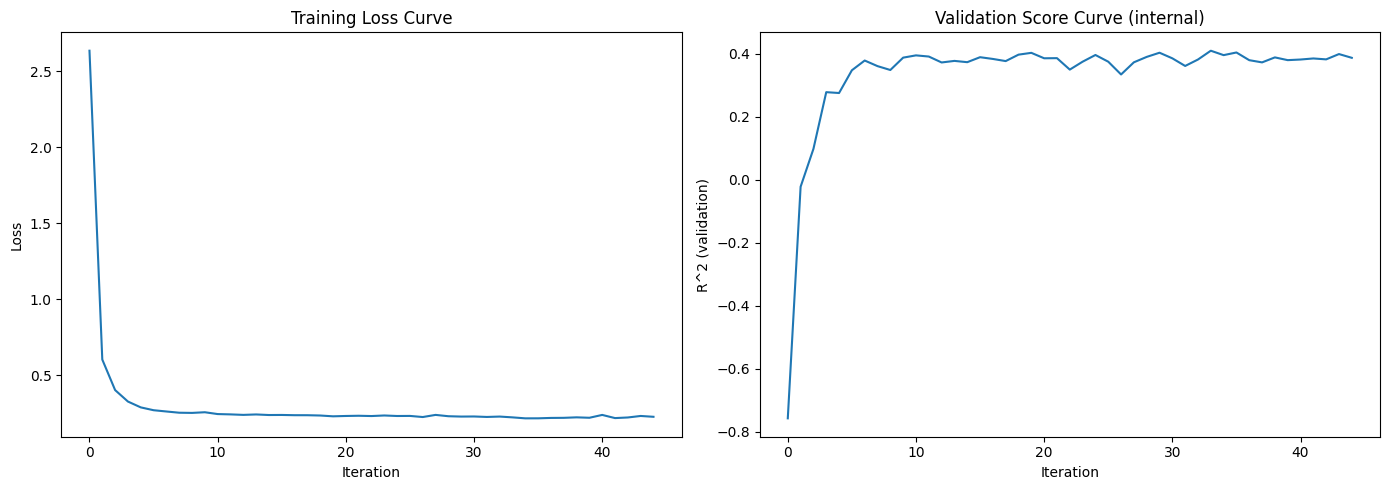

In [ ]:
# ------------------------------------------------------------------
# Plot loss curve (and validation score curve, since early_stopping=True exposes it)
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(nn_model.loss_curve_)
axes[0].set_title('Training Loss Curve')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Loss')

axes[1].plot(nn_model.validation_scores_)
axes[1].set_title('Validation Score Curve (internal)')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('R^2 (validation)')

plt.tight_layout()
plt.show()

Early stopping did exactly what it was supposed to: it stopped training at iteration 45 instead of letting it run toward memorization, and the gap shrank from ~0.30 down to ~0.10.

With this configuration we have obtained the best results so far.

## Comparing with a LinearRegression model.

In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression

# Create and train a LinearRegression model
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)

# Making predictions
lr_pred = lr_model.predict(X_test_scaled)

# Evaluating LinearRegresion model
lr_mse = mean_squared_error(y_test, lr_pred)
lr_r2 = r2_score(y_test, lr_pred)

print("\nResults from Linear Regression:")
print(f"Linear Regression MSE: {lr_mse}")
print(f"Linear Regression R^2: {lr_r2}")
print("Evaluation (training set): %f" %lr_model.score(X_train_scaled, y_train))
print("Evaluation (test set): %f" %lr_model.score(X_test_scaled, y_test))


Results from Linear Regression:
Linear Regression MSE: 0.5075706569742575
Linear Regression R^2: 0.29017030042054215
Evaluation (training set): 0.297477
Evaluation (test set): 0.290170


Let's try now Linear Regression with some regularized linear variants — Ridge and Lasso.

In [ ]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import cross_val_score

for alpha in [0.01, 0.1, 1.0, 10.0]:
    ridge = Ridge(alpha=alpha)
    scores = cross_val_score(ridge, X_train_scaled, y_train, cv=5, scoring='r2')
    print(f"Ridge alpha={alpha}: mean CV R^2 = {scores.mean():.4f}")

for alpha in [0.001, 0.01, 0.1, 1.0]:
    lasso = Lasso(alpha=alpha)
    scores = cross_val_score(lasso, X_train_scaled, y_train, cv=5, scoring='r2')
    print(f"Lasso alpha={alpha}: mean CV R^2 = {scores.mean():.4f}")

Ridge alpha=0.01: mean CV R^2 = 0.2904
Ridge alpha=0.1: mean CV R^2 = 0.2904
Ridge alpha=1.0: mean CV R^2 = 0.2904
Ridge alpha=10.0: mean CV R^2 = 0.2906
Lasso alpha=0.001: mean CV R^2 = 0.2905
Lasso alpha=0.01: mean CV R^2 = 0.2843
Lasso alpha=0.1: mean CV R^2 = 0.2308
Lasso alpha=1.0: mean CV R^2 = -0.0031


Let's try now Linear Regression with some polynomial features to capture some non-linearity

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

poly_pipeline = Pipeline([
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('lr', LinearRegression())
])

poly_pipeline.fit(X_train_scaled, y_train)
poly_pred = poly_pipeline.predict(X_test_scaled)

poly_mse = mean_squared_error(y_test, poly_pred)
poly_r2 = r2_score(y_test, poly_pred)
print(f"Polynomial (degree=2) Test R^2: {poly_r2:.4f}, MSE: {poly_mse:.4f}")

Polynomial (degree=2) Test R^2: 0.3304, MSE: 0.4788


Polynomial features gave the best result among linear-family models (0.3304), a real jump above the 0.29 ceiling the other linear approaches were stuck at. This is a meaningful data point: it confirms there genuinely is non-linear structure in this dataset that a purely linear model can't reach.

The MLP does win on test R² and test MSE — that's real, even on the best result from LinearRegression that introduces actually non-linear capacity because of the PolynomialFeatures. This is evidence that there's genuine non-linear structure in the data that the MLP is capturing and linear regression can't.

So the MLP is outperforming the linear baseline by a real margin, and the early stopping is keeping it well-controlled. We'll continue working with this model, let's just implement a couple of extra details to see if we can further improve the results.

First, let's try a light alpha sweep to see if a bit more regularization helps prevent overfitting and pushes test R² up a bit more.

In [ ]:
alphas = [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]

results = []

for alpha in alphas:
    model = MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        learning_rate_init=0.01,
        max_iter=1000,
        alpha=alpha,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=42
    )

    model.fit(X_train_scaled, y_train)

    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)

    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    test_mse = mean_squared_error(y_test, y_test_pred)
    gap = train_r2 - test_r2

    results.append({
        'alpha': alpha,
        'n_iter': model.n_iter_,
        'train_r2': train_r2,
        'test_r2': test_r2,
        'test_mse': test_mse,
        'train_test_gap': gap
    })

    print(f"alpha={alpha:<8} | n_iter={model.n_iter_:<4} | "
          f"train_r2={train_r2:.4f} | test_r2={test_r2:.4f} | "
          f"test_mse={test_mse:.4f} | gap={gap:.4f}")

results_df = pd.DataFrame(results)

# ------------------------------------------------------------------
# Best alpha by test R^2
# ------------------------------------------------------------------
best_row = results_df.loc[results_df['test_r2'].idxmax()]
print(f"\nBest alpha by test R^2: {best_row['alpha']} (test_r2={best_row['test_r2']:.4f})")


alpha=0.0001   | n_iter=45   | train_r2=0.4625 | test_r2=0.3668 | test_mse=0.4528 | gap=0.0957
alpha=0.0005   | n_iter=31   | train_r2=0.4330 | test_r2=0.3511 | test_mse=0.4640 | gap=0.0819
alpha=0.001    | n_iter=31   | train_r2=0.4325 | test_r2=0.3506 | test_mse=0.4643 | gap=0.0819
alpha=0.005    | n_iter=55   | train_r2=0.4752 | test_r2=0.3722 | test_mse=0.4489 | gap=0.1029
alpha=0.01     | n_iter=31   | train_r2=0.4315 | test_r2=0.3536 | test_mse=0.4622 | gap=0.0780
alpha=0.05     | n_iter=31   | train_r2=0.4281 | test_r2=0.3488 | test_mse=0.4656 | gap=0.0793
alpha=0.1      | n_iter=31   | train_r2=0.4298 | test_r2=0.3500 | test_mse=0.4648 | gap=0.0797

Best alpha by test R^2: 0.005 (test_r2=0.3722)


And finally let's rerun this new config through 5-fold cross-validation to confirm the improvement holds up beyond this one split we did at first:

In [ ]:
import numpy as np
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

# ------------------------------------------------------------------
# Pipeline: scaler + MLP bundled together, so each CV fold
# fits the scaler only on that fold's training data (no leakage)
# ------------------------------------------------------------------
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        learning_rate_init=0.01,
        max_iter=1000,
        alpha=0.005,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=42
    ))
])

# ------------------------------------------------------------------
# 5-fold cross-validation
# Use X_train (unscaled) and y_train here, since the pipeline
# handles scaling internally per fold.
# ------------------------------------------------------------------
kf = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    pipeline,
    X_train,   # unscaled features
    y_train,
    cv=kf,
    scoring=['r2', 'neg_mean_squared_error'],
    return_train_score=True
)

r2_scores = cv_results['test_r2']
mse_scores = -cv_results['test_neg_mean_squared_error']
train_r2_scores = cv_results['train_r2']

print("Per-fold Test R^2:      ", np.round(r2_scores, 4))
print("Per-fold Train R^2:     ", np.round(train_r2_scores, 4))
print("Per-fold Test MSE:      ", np.round(mse_scores, 4))
print()
print(f"Mean Test R^2:  {r2_scores.mean():.4f}  (+/- {r2_scores.std():.4f})")
print(f"Mean Train R^2: {train_r2_scores.mean():.4f}  (+/- {train_r2_scores.std():.4f})")
print(f"Mean Test MSE:  {mse_scores.mean():.4f}  (+/- {mse_scores.std():.4f})")
print(f"Mean Train-Test gap: {(train_r2_scores.mean() - r2_scores.mean()):.4f}")

Per-fold Test R^2:       [0.3949 0.3612 0.3757 0.3501 0.3342]
Per-fold Train R^2:      [0.4737 0.4477 0.4386 0.443  0.4437]
Per-fold Test MSE:       [0.4477 0.4756 0.5009 0.5392 0.5011]

Mean Test R^2:  0.3632  (+/- 0.0209)
Mean Train R^2: 0.4493  (+/- 0.0125)
Mean Test MSE:  0.4929  (+/- 0.0304)
Mean Train-Test gap: 0.0861


##Final Conclusions

This last test gives us a robust estimate of how the model performs across different slices of the training data.

Looking at the Mean Test R^2 and its std: As the std is small (0.0209) this tells us our earlier single-split result (0.3722) was reasonably representative. A large std would mean the model's performance varies a lot depending on which data it sees.

Comparing mean Test R² (0.3632) to our original 0.3722, it is very close, so that confirms the alpha=0.005 result generalizes.

So, clearly the MLPRegressor outperforms the Linear Regression and this is very likely because there's non-linear structure in the data that the MLP is capturing and linear regression can't, for example, in the boxplots plotted above there are some features like Free sulfur dioxide / total sulfur dioxide that show a slight rise-then-fall pattern (increase from quality 3 to mid-range, then decrease toward 8-9), rather than a monotonic trend. This "inverted U" shape suggests a non-linear relationship, NNs can capture this kind of non-monotonic relationship more naturally.



      Model	                                              Test R²	Test MSE	Train R²	Train-Test Gap
      LinearRegression (baseline)	                      0.2902	0.5076	    0.2975	    ~0.007
      Ridge (best: alpha=10.0)	                          0.2906 (CV)	—	    —	          —
      Lasso (best: alpha=0.001)	                          0.2905 (CV)	—	    —	          —
      Polynomial (degree=2) + LinearRegression	          0.3304	0.4788	    —	          —
      MLPRegressor (64,32), alpha=0.005, early stopping.  0.3632 (CV mean)	0.4929 (CV mean)	0.4493 (CV mean)	0.0861